# 01 — Exploration des données (EDA) · RadarML Lite, Track B

**Objectif :** comprendre à quoi ressemble chaque classe, comment le bruit la dégrade, et préparer
les choix de représentation temps-fréquence (STFT) avant de construire un modèle.

**Règles respectées dans ce notebook :**
- uniquement des pulses **train** (la validation sert à évaluer, pas à explorer pour régler) ;
- les noms de fichiers servent seulement aux labels et à l'analyse, **jamais comme entrée de modèle** ;
- les SNR sont des **requested SNR (dB)**, générés avec le bruitage officiel (`radarml.noise`).

Prérequis : `python scripts/setup_data.py` a été lancé (données dans `data/raw/recorded_dataset`).

In [1]:
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from radarml.constants import CLASSES, SAMPLE_RATE_HZ, REQUESTED_SNRS_DB
from radarml.manifest import load_manifest, select, class_counts
from radarml.noise import degrade, degrade_official, to_complex

DATA = ROOT / "data" / "raw" / "recorded_dataset"
refs = load_manifest(DATA, ROOT / "data" / "manifest" / "split_manifest.csv")
train = select(refs, "train")
print(f"{len(refs)} pulses au total | train: {len(train)} | validation: {len(refs) - len(train)}")

FS = SAMPLE_RATE_HZ
T_US = np.arange(16_800) / FS * 1e6          # axe temps en microsecondes
_cache = {}

def load_row(ref):
    # Une ligne int16 entrelacée (33600,) d'un pulse, via memmap.
    if ref.file not in _cache:
        _cache[ref.file] = np.load(DATA / ref.file, mmap_mode="r", allow_pickle=False)
    return np.asarray(_cache[ref.file][0, ref.pulse_index])

def pulse_iq(ref, snr=None):
    # Complexe (16800,) au SNR demandé (None = enregistrement sans bruit ajouté).
    row = load_row(ref)
    if snr is not None:
        row = degrade_official(row, ref.source_file, snr, ref.pulse_index)
    return to_complex(row)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

66000 pulses au total | train: 52800 | validation: 13200


## 1. Vue d'ensemble : classes et configurations

Chaque fichier est une **configuration** (modulation × durée × bande × fréquence). Les paramètres
lus dans le nom de fichier servent ici uniquement à décrire le dataset.

In [2]:
def describe(name):
    parts = name.replace("_recorded.npy", "").split("_")
    return dict(duration_us=int(parts[0].removesuffix("us")),
                bandwidth_mhz=int(parts[2].removesuffix("Mhz")),
                subtype=parts[1])

files = sorted({r.file for r in train})
configs = pd.DataFrame([{"file": f, "label": next(r.label for r in train if r.file == f), **describe(f)}
                        for f in files])

summary = pd.DataFrame({
    "configurations": configs.groupby("label").size(),
    "pulses_train": pd.Series(class_counts(train)),
})
summary["part_du_train_%"] = (100 * summary.pulses_train / summary.pulses_train.sum()).round(1)
display(summary)
display(pd.crosstab(configs.label, configs.duration_us).rename_axis(columns="durée (µs)"))
display(pd.crosstab(configs.label, configs.bandwidth_mhz).rename_axis(columns="bande (MHz)"))

,configurations,pulses_train,part_du_train_%
barker,72,5760,10.9
cw,12,960,1.8
fmcw,96,7680,14.5
fsk,192,15360,29.1
hyp,96,7680,14.5
nlfm,96,7680,14.5
quad,96,7680,14.5


durée (µs),10,50,100
label,,,
barker,24,24,24
cw,4,4,4
fmcw,32,32,32
fsk,64,64,64
hyp,32,32,32
nlfm,32,32,32
quad,32,32,32


bande (MHz),0,10,20,40,80
label,,,,,
barker,72,0,0,0,0
cw,12,0,0,0,0
fmcw,0,30,30,30,6
fsk,0,60,60,60,12
hyp,0,30,30,30,6
nlfm,0,30,30,30,6
quad,0,30,30,30,6


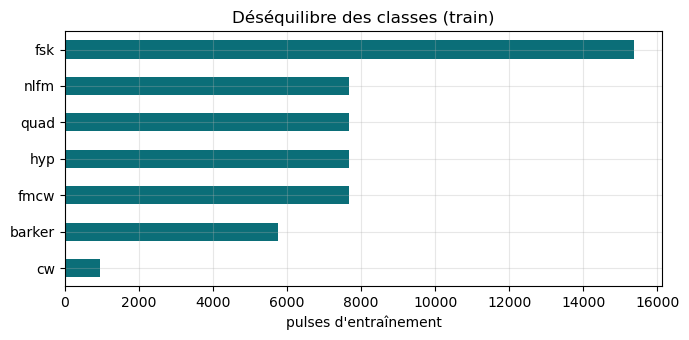

Ratio fsk / cw : 16.0


In [3]:
ax = summary.pulses_train.sort_values().plot.barh(figsize=(7, 3.5), color="#0B6E78")
ax.set(xlabel="pulses d'entraînement", title="Déséquilibre des classes (train)")
plt.tight_layout(); plt.show()
print("Ratio fsk / cw :", summary.pulses_train["fsk"] / summary.pulses_train["cw"])

**À retenir :** la métrique est une *balanced accuracy* (chaque classe pèse autant).
`cw` est très minoritaire → prévoir pondération de la loss ou échantillonnage équilibré.

## 2. Un pulse dans le temps : I, Q, amplitude

Un enregistrement dure 140 µs ; le pulse (10, 50 ou 100 µs) est centré, entouré de bruit.

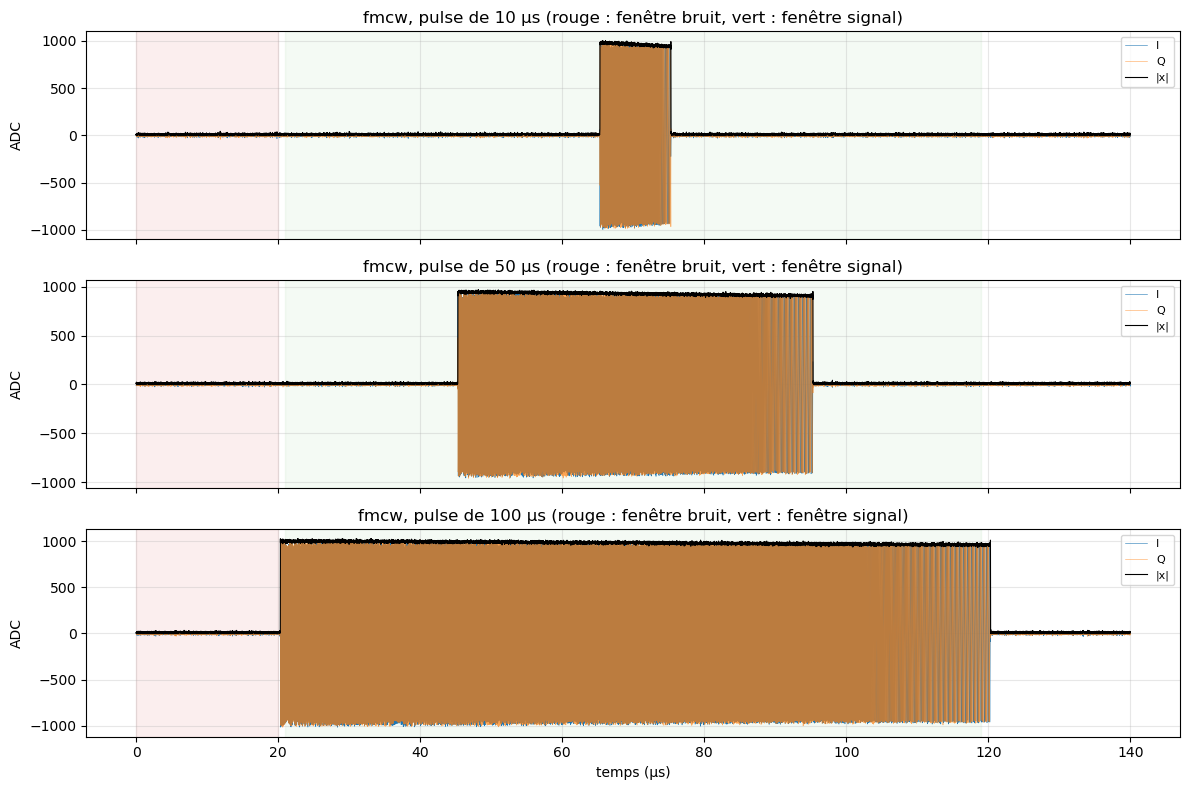

In [4]:
def first(label, duration):
    return next(r for r in train if r.label == label and describe(r.file)["duration_us"] == duration)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, duration in zip(axes, (10, 50, 100)):
    ref = first("fmcw", duration)
    iq = pulse_iq(ref)
    ax.plot(T_US, iq.real, lw=0.4, label="I")
    ax.plot(T_US, iq.imag, lw=0.4, label="Q", alpha=0.7)
    ax.plot(T_US, np.abs(iq), lw=0.8, c="k", label="|x|")
    ax.axvspan(0, 20, color="tab:red", alpha=0.08)
    ax.axvspan(21, 119, color="tab:green", alpha=0.05)
    ax.set(title=f"fmcw, pulse de {duration} µs (rouge : fenêtre bruit, vert : fenêtre signal)", ylabel="ADC")
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("temps (µs)")
plt.tight_layout(); plt.show()

**Observation clé :** le SNR officiel est estimé sur 21–119 µs. Pour un pulse de 10 µs, l'essentiel
de cette fenêtre est du bruit, donc le **SNR réel dans le pulse est bien plus faible** que le SNR demandé.

## 3. Spectrogrammes par classe et par SNR

Un exemple par classe, au même pulse, à quatre SNR demandés. Spectre **bilatéral** (signal complexe).

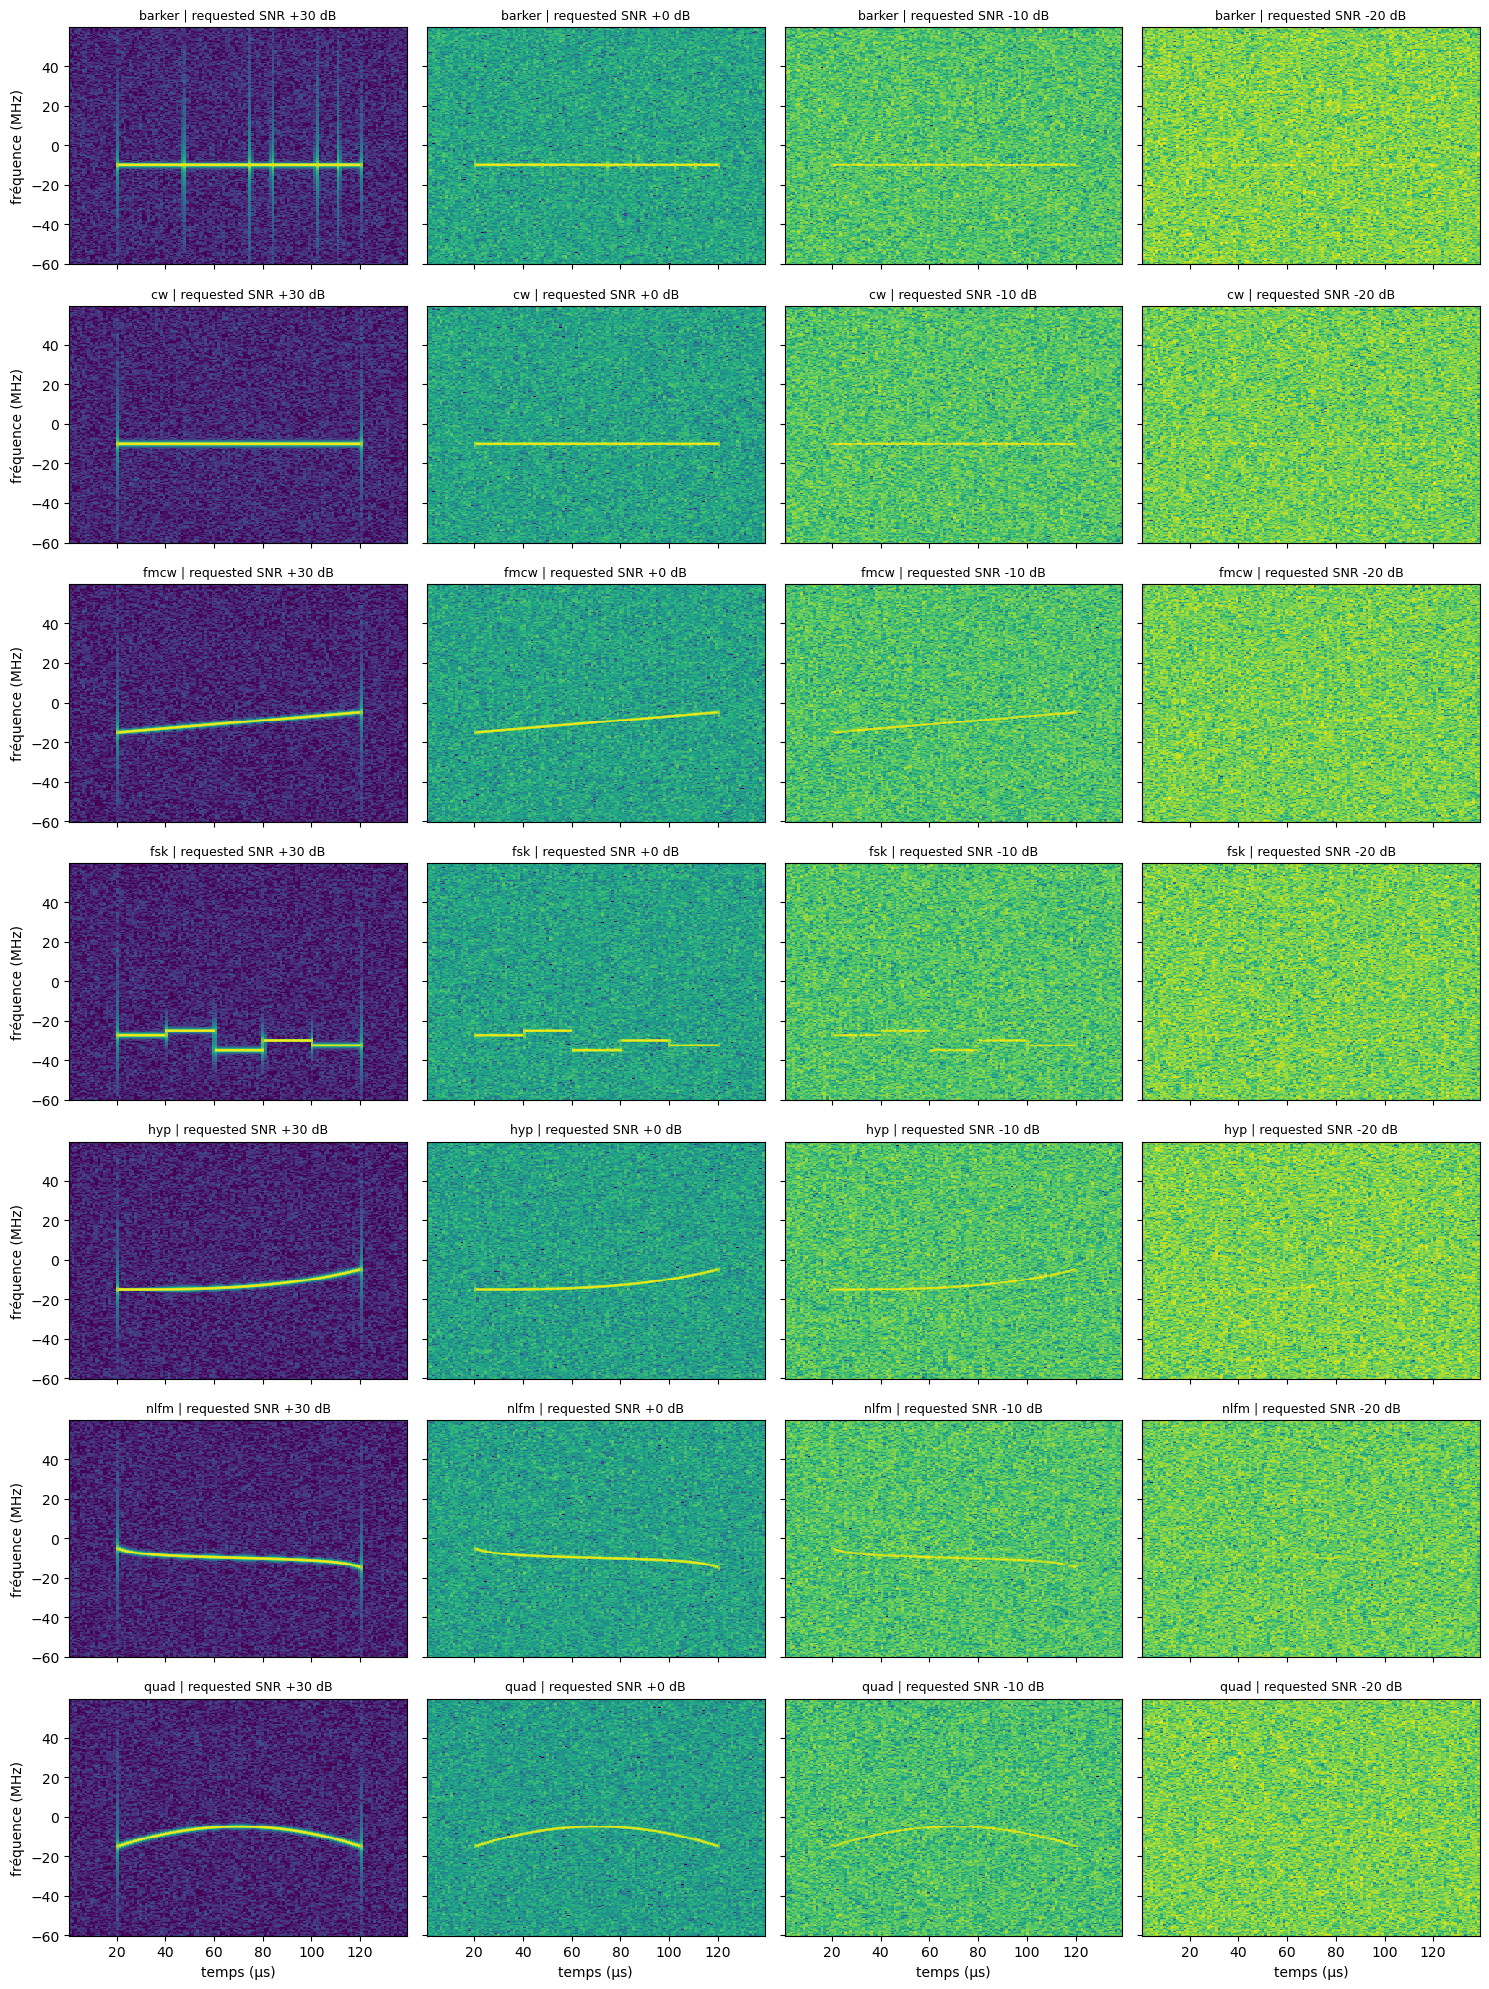

In [5]:
def spectrogram(iq, n_fft=256, hop=128):
    # STFT bilatérale -> (freq_MHz, temps_us, puissance_dB normalisée au max).
    frames = np.lib.stride_tricks.sliding_window_view(iq, n_fft)[::hop]
    spec = np.fft.fftshift(np.fft.fft(frames * np.hanning(n_fft), axis=1), axes=1)
    power = np.abs(spec) ** 2
    db = 10 * np.log10(power / power.max() + 1e-12)
    t = (np.arange(len(frames)) * hop + n_fft / 2) / FS * 1e6
    f = np.fft.fftshift(np.fft.fftfreq(n_fft, 1 / FS)) / 1e6
    return f, t, db.T

def show_spec(ax, iq, title, n_fft=256, hop=128, vmin=-60):
    f, t, db = spectrogram(iq, n_fft, hop)
    ax.pcolormesh(t, f, db, shading="auto", vmin=vmin, vmax=0, cmap="viridis")
    ax.set_title(title, fontsize=9); ax.grid(False)

examples = {c: first(c, 100) for c in CLASSES}
snrs = [30, 0, -10, -20]
fig, axes = plt.subplots(len(CLASSES), len(snrs), figsize=(15, 20), sharex=True, sharey=True)
for i, (cls, ref) in enumerate(examples.items()):
    for j, snr in enumerate(snrs):
        show_spec(axes[i, j], pulse_iq(ref, snr), f"{cls} | requested SNR {snr:+d} dB")
for ax in axes[-1]: ax.set_xlabel("temps (µs)")
for ax in axes[:, 0]: ax.set_ylabel("fréquence (MHz)")
plt.tight_layout(); plt.show()

**À noter ici :** quelles classes se distinguent facilement à l'œil ? lesquelles se ressemblent
(les chirps `fmcw` / `hyp` / `quad` / `nlfm`) ? à partir de quel SNR le pulse disparaît-il ?

## 4. Variabilité intra-classe

Une même classe change beaucoup selon la bande, la fréquence centrale et la durée.
Le modèle doit reconnaître la *forme* de la modulation, pas une configuration.

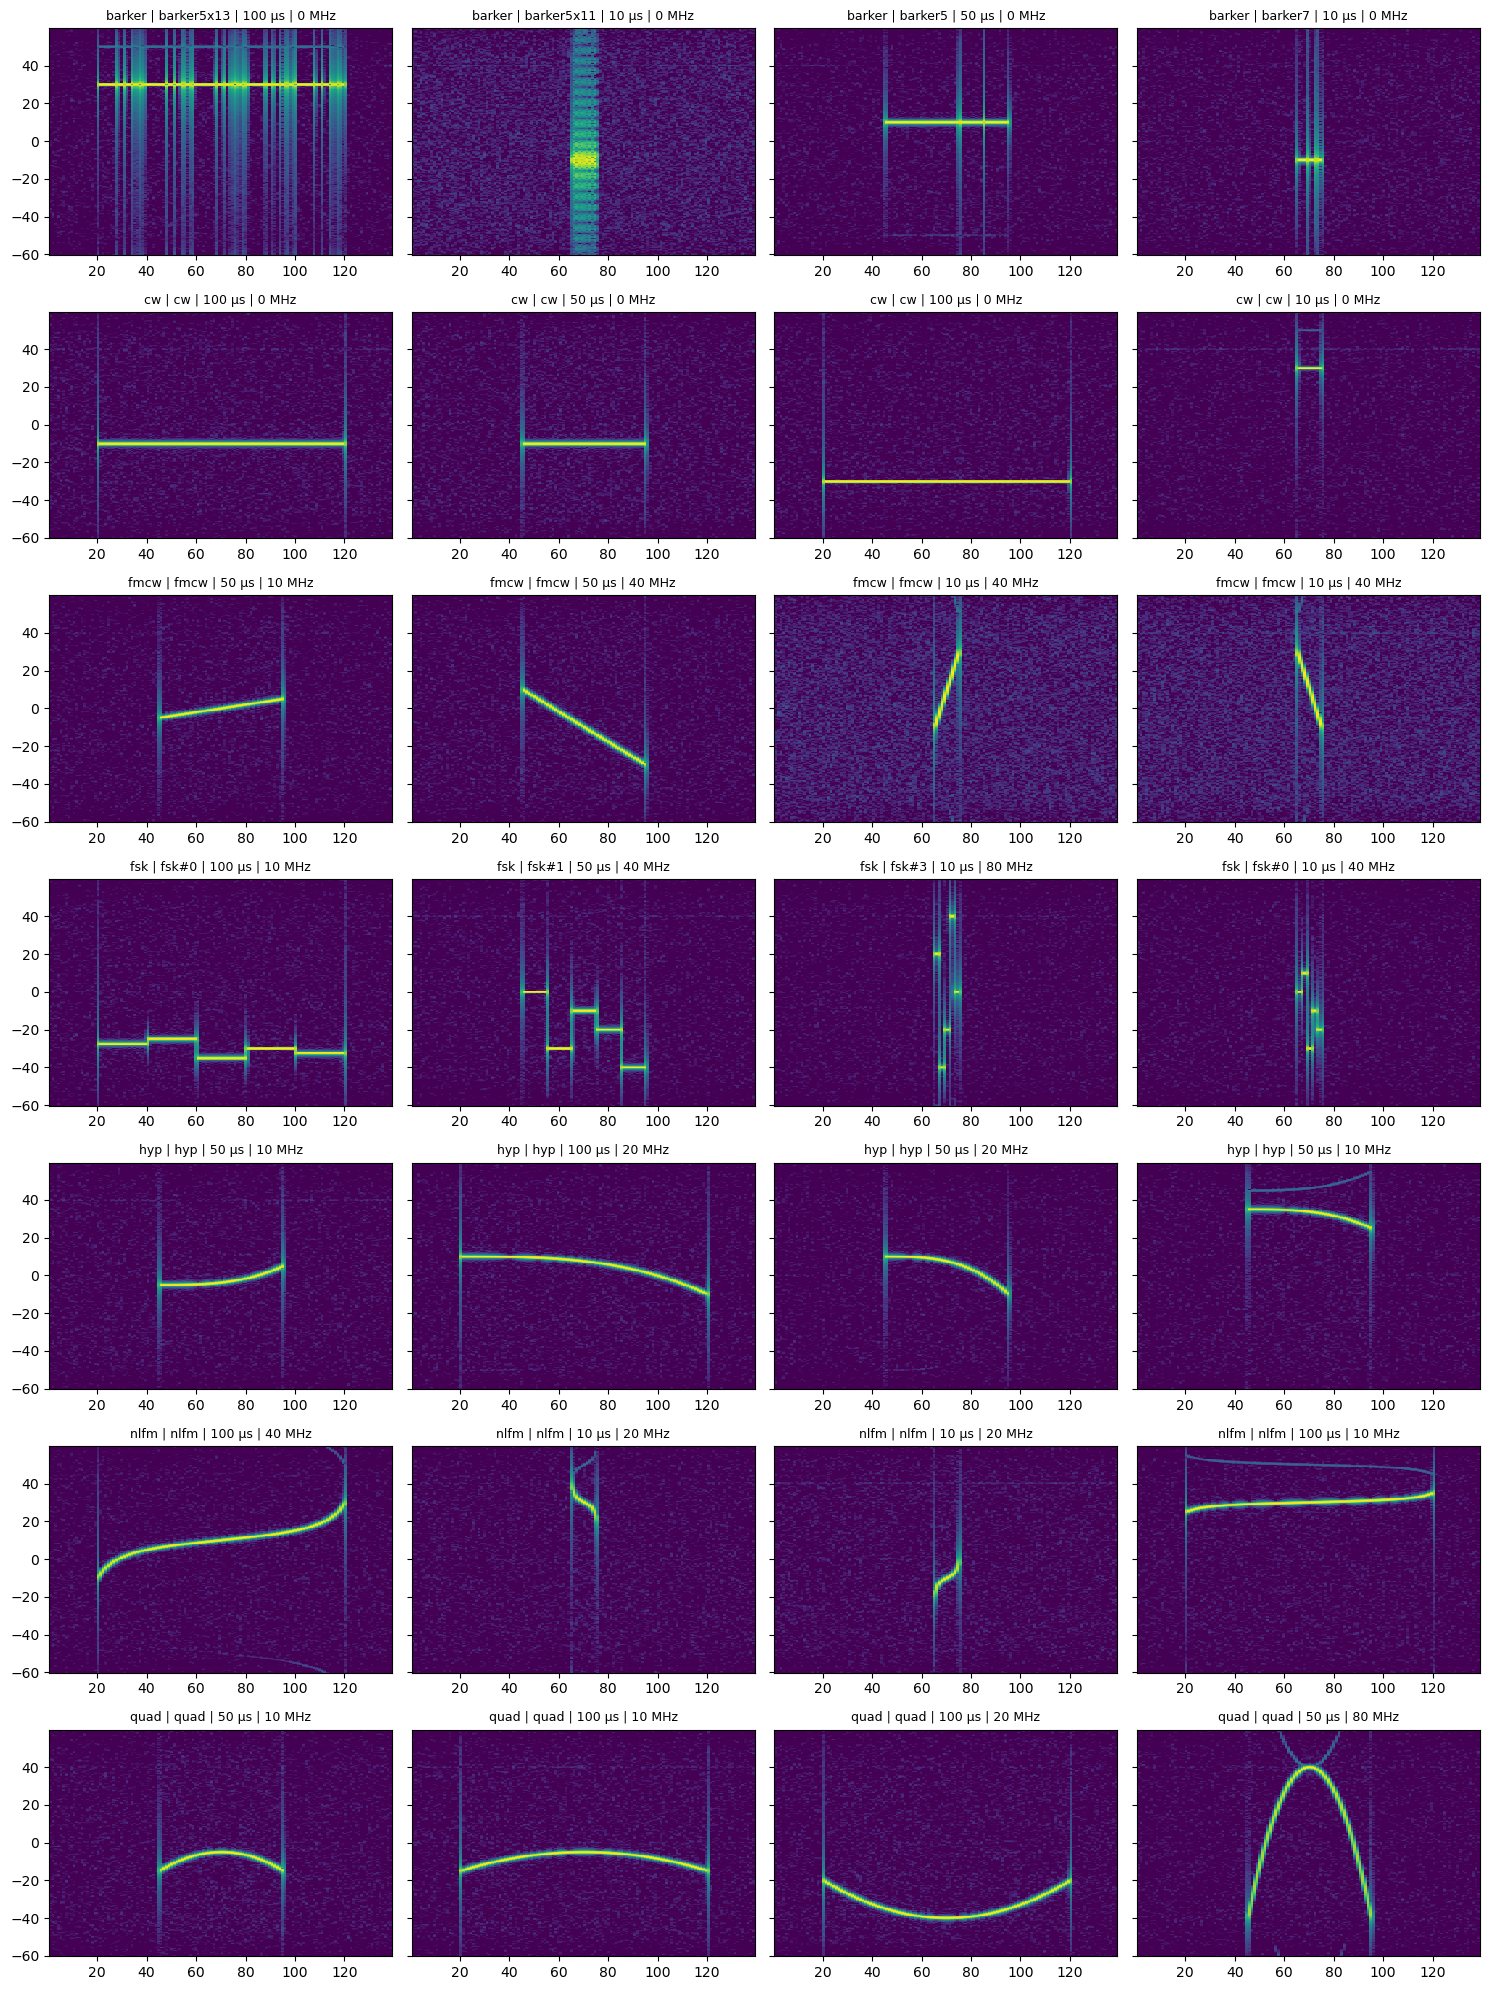

In [6]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(15, 20), sharey=True)
for i, cls in enumerate(CLASSES):
    candidates = sorted({r.file for r in train if r.label == cls})
    for j, name in enumerate(rng.choice(candidates, size=4, replace=False)):
        ref = next(r for r in train if r.file == name)
        d = describe(name)
        show_spec(axes[i, j], pulse_iq(ref), f"{cls} | {d['subtype']} | {d['duration_us']} µs | {d['bandwidth_mhz']} MHz")
plt.tight_layout(); plt.show()

## 5. Choix de la fenêtre STFT (compromis temps / fréquence)

Fenêtre courte → bonne résolution temporelle (sauts FSK, transitions de phase Barker).
Fenêtre longue → bonne résolution fréquentielle (tons proches, pentes de chirp).

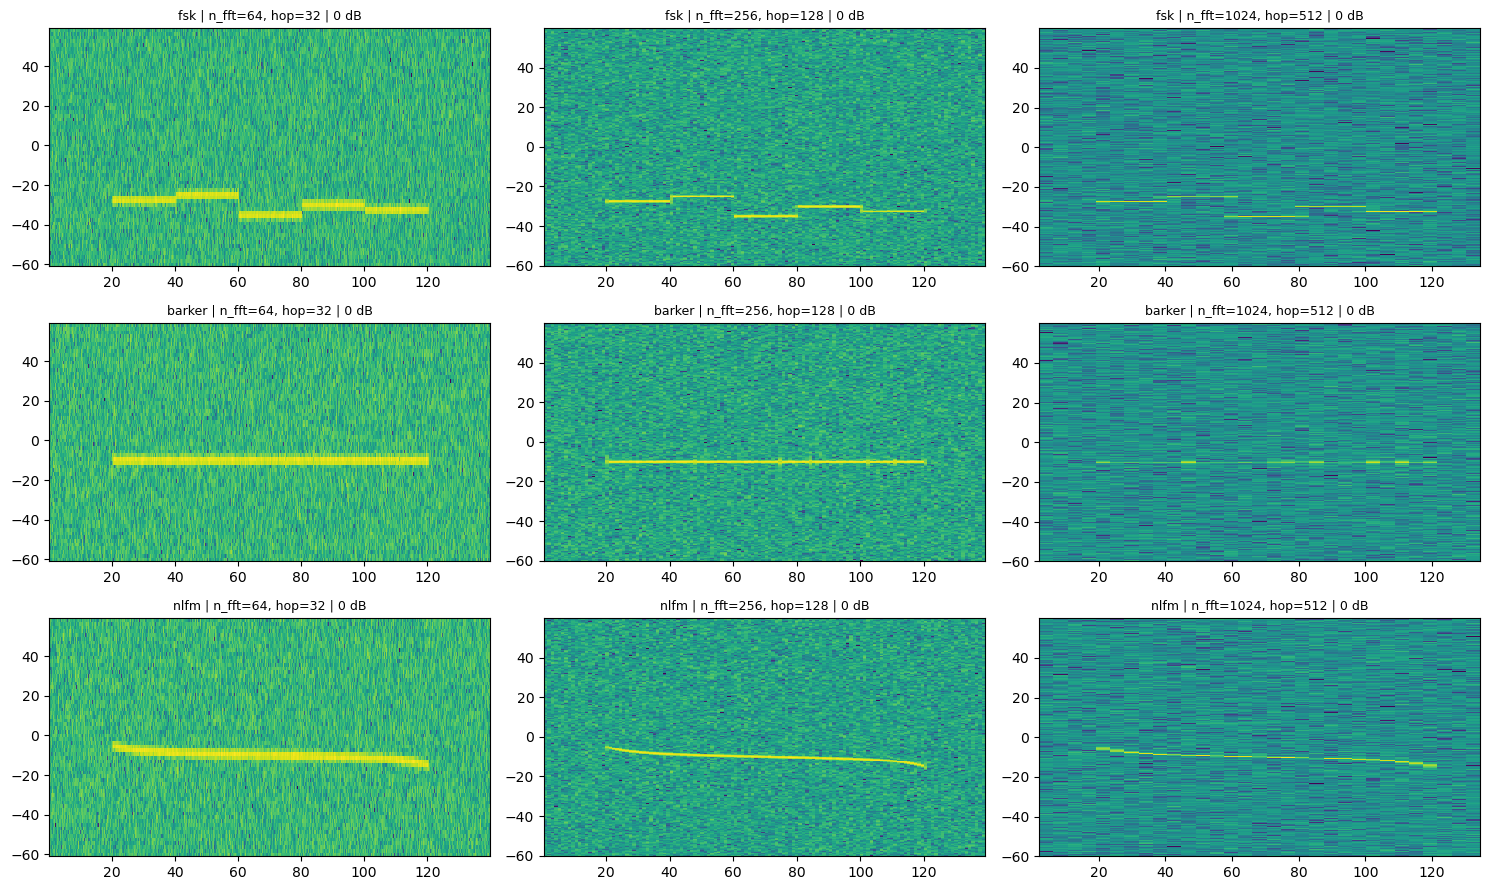

n_fft=   64: résolution fréquence  1875.0 kHz | fenêtre  0.53 µs | 524 trames
n_fft=  256: résolution fréquence   468.8 kHz | fenêtre  2.13 µs | 130 trames
n_fft= 1024: résolution fréquence   117.2 kHz | fenêtre  8.53 µs | 31 trames


In [7]:
windows = [64, 256, 1024]
fig, axes = plt.subplots(3, len(windows), figsize=(15, 9))
for i, cls in enumerate(["fsk", "barker", "nlfm"]):
    iq = pulse_iq(examples[cls], 0)
    for j, n_fft in enumerate(windows):
        show_spec(axes[i, j], iq, f"{cls} | n_fft={n_fft}, hop={n_fft // 2} | 0 dB", n_fft, n_fft // 2)
plt.tight_layout(); plt.show()
for n_fft in windows:
    print(f"n_fft={n_fft:5d}: résolution fréquence {FS / n_fft / 1e3:7.1f} kHz | "
          f"fenêtre {n_fft / FS * 1e6:5.2f} µs | {1 + (16_800 - n_fft) // (n_fft // 2)} trames")

## 6. Pulses courts vs longs face au bruit

Même classe, même SNR demandé : comparer un pulse de 10 µs et un de 100 µs.

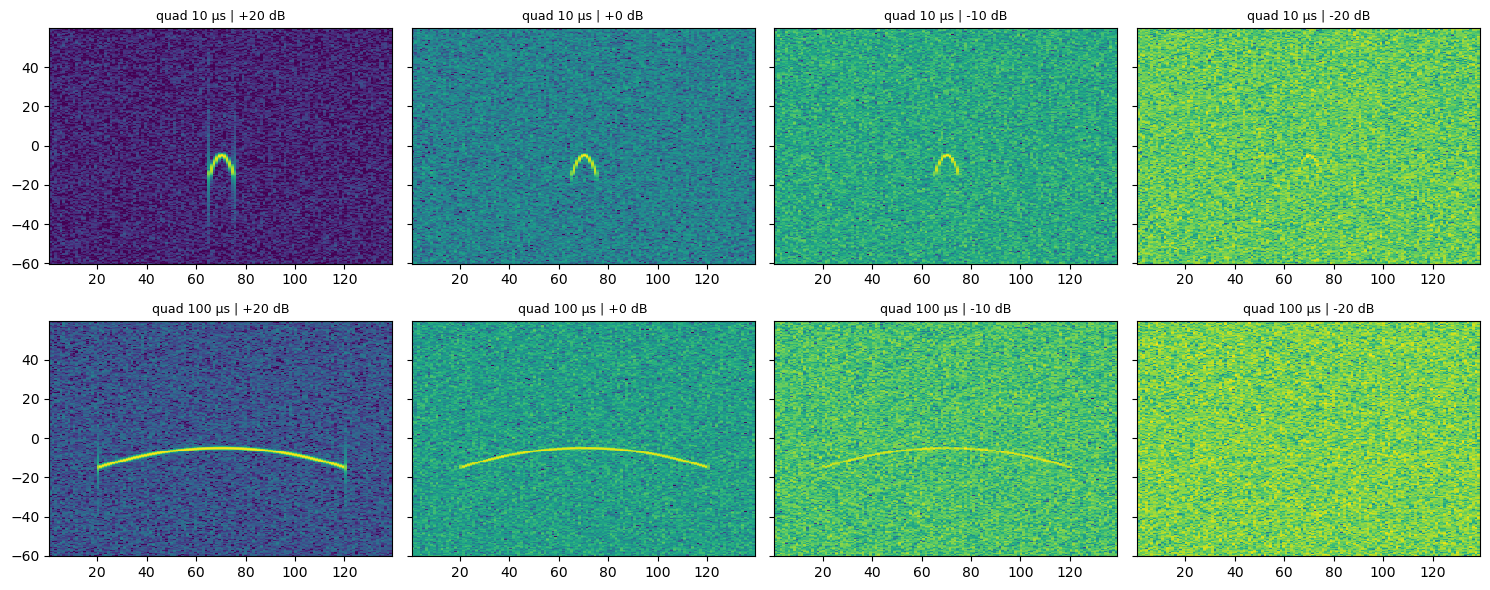

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for i, duration in enumerate((10, 100)):
    ref = first("quad", duration)
    for j, snr in enumerate([20, 0, -10, -20]):
        show_spec(axes[i, j], pulse_iq(ref, snr), f"quad {duration} µs | {snr:+d} dB")
plt.tight_layout(); plt.show()

## 7. Recherche de raccourcis (shortcuts) d'acquisition

Les organisateurs demandent si le modèle exploite la structure de la forme d'onde ou des
**caractéristiques incidentes** de l'acquisition. On vérifie si le niveau de bruit ou la puissance
diffèrent selon la classe : si oui, la normalisation par pulse devient indispensable.

noise_db                                          source_snr_db        \
          count  mean  std   min   25%   50%   75%   max         count  mean   
label                                                                          
barker    286.0  21.3  0.3  20.6  21.1  21.3  21.5  21.9         286.0  34.3   
cw         47.0  21.4  0.4  20.8  21.0  21.3  21.7  21.9          47.0  33.6   
fmcw      391.0  21.4  0.2  20.7  21.2  21.4  21.6  22.0         391.0  33.9   
fsk       763.0  21.3  0.2  20.6  21.1  21.2  21.4  21.8         763.0  34.2   
hyp       373.0  21.4  0.3  20.8  21.3  21.5  21.6  22.0         373.0  33.9   
nlfm      384.0  21.4  0.3  20.7  21.2  21.5  21.6  22.1         384.0  33.7   
quad      374.0  21.4  0.2  20.8  21.3  21.5  21.6  22.0         374.0  34.0   

                                           
        std   min   25%   50%   75%   max  
label                                      
barker  4.2  27.9  28.7  35.6  38.3  39.0  
cw      4.2  27.5  28.2  34.8  37.6  38.7  
fmcw    4.2  27.8  28.4  35.3  38.0  38.7  
fsk     4.2  28.0  28.8  35.6  38.4  39.3  
hyp     4.2  27.8  28.4  35.3  38.0  38.7  
nlfm    4.2  27.3  28.3  34.9  37.7  38.5  
quad    4.2  27.8  28.5  35.3  38.1  38.8

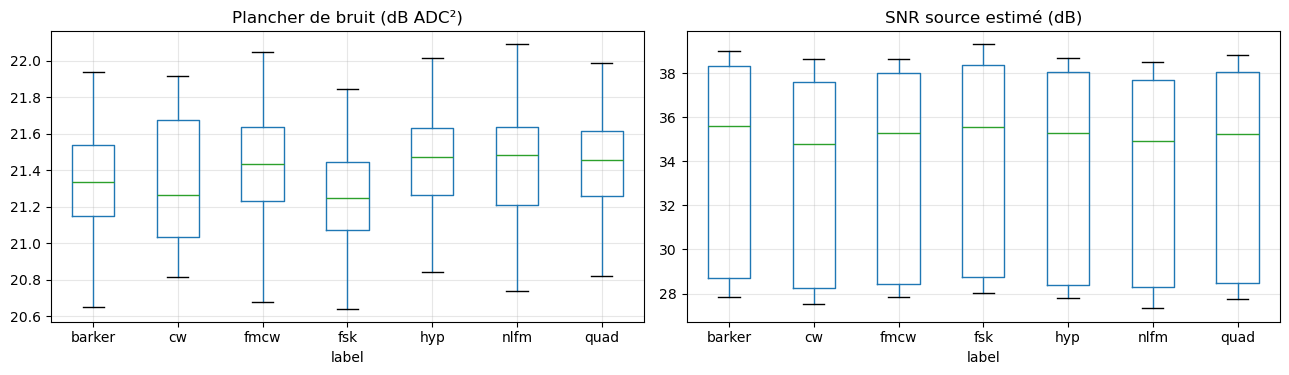

In [9]:
sample = [r for r in train if r.pulse_index % 20 == 0]          # 4 pulses par configuration
rows = []
for ref in sample:
    iq = pulse_iq(ref)
    p = np.abs(iq) ** 2
    noise = p[: int(20e-6 * FS)].mean()
    signal = p[int(21e-6 * FS): int(119e-6 * FS)].mean() - noise
    rows.append(dict(label=ref.label, noise_db=10 * np.log10(noise),
                     source_snr_db=10 * np.log10(max(signal, 1e-9) / noise),
                     duration_us=describe(ref.file)["duration_us"]))
stats = pd.DataFrame(rows)
display(stats.groupby("label")[["noise_db", "source_snr_db"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
stats.boxplot(column="noise_db", by="label", ax=axes[0]); axes[0].set_title("Plancher de bruit (dB ADC²)")
stats.boxplot(column="source_snr_db", by="label", ax=axes[1]); axes[1].set_title("SNR source estimé (dB)")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Lecture :** le SNR source plafonne ce que +30 dB peut atteindre (si la cible dépasse le SNR
source, aucun bruit n'est ajouté). Un plancher de bruit ou une puissance très différents selon la
classe seraient un raccourci potentiel à neutraliser (normalisation par pulse).

## 8. Effet de l'écrêtage int16 à très bas SNR

À −30 dB, le bruit ajouté dépasse parfois la plage int16 et est écrêté (≈ 5,4 % des valeurs).

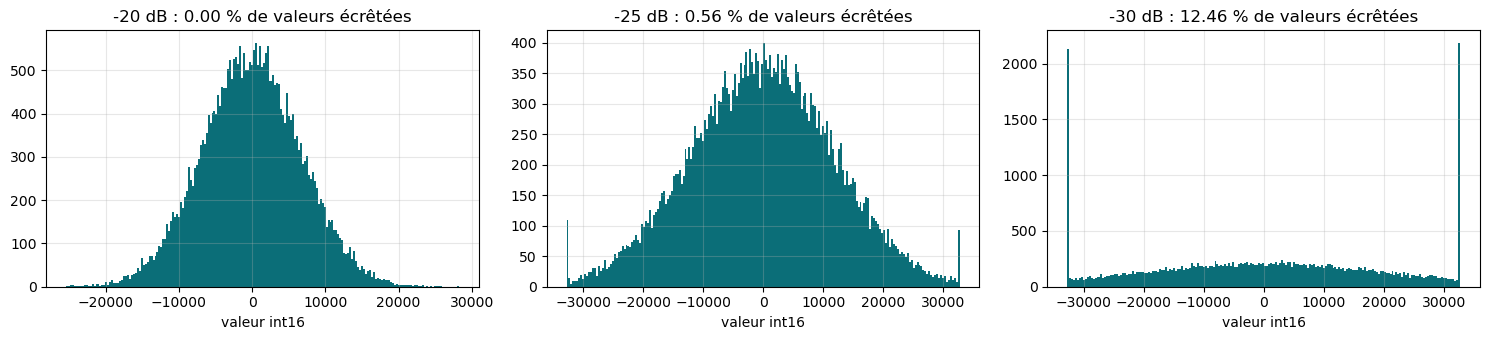

In [10]:
ref = examples["cw"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, snr in zip(axes, (-20, -25, -30)):
    row = degrade_official(load_row(ref), ref.source_file, snr, ref.pulse_index)
    clipped = np.mean((row == 32767) | (row == -32768)) * 100
    ax.hist(row.astype(float), bins=200, color="#0B6E78")
    ax.set(title=f"{snr:+d} dB : {clipped:.2f} % de valeurs écrêtées", xlabel="valeur int16")
plt.tight_layout(); plt.show()

## 9. Conclusions (à compléter par l'équipe)

| Question | Réponse |
| --- | --- |
| Classes faciles / difficiles à l'œil ? | |
| Paires de classes confondues ? | |
| SNR où le pulse devient invisible (10 µs vs 100 µs) ? | |
| Taille de fenêtre STFT qui semble la plus informative ? | |
| Raccourcis d'acquisition détectés ? | |
| Décisions pour le pipeline du Day 1 | |